# Lab 4 · Course Navigator
## Notebook 5 — From trained model to deployed app

Modules 7–8 ask whether a model can become a useful application and whether adaptation was worthwhile. Here we connect the saved model to a public app. The work includes preprocessing, source attribution, loading behavior, testing and an honest model card—not just a predict button.

**Key question:** How do we turn an evaluated checkpoint into the same predictions in a real app?

### Learning objectives
- Define an inference contract and save all required artifacts.
- Export ONNX and compare it numerically against PyTorch.
- Separate model routing from source retrieval and handle uncertain input.
- Run, deploy, smoke-test and maintain the browser application.

### Classroom route and independent study

Plan about **35 minutes** for the guided route. Read the explanations, predict the output, then run each cell in order. Exercises and worked answers support a slower independent review. Saved results come from real CPU runs; seeds reduce variation but cannot guarantee identical numbers across machines.

### Setup

Use Python 3.12 in a dedicated environment. Download the **complete project ZIP** from the repository, extract it, install `requirements.txt`, and select that environment as your Jupyter kernel. In Colab, the first cell clones the project when needed. If imports fail, run `%pip install -r /content/course-navigator/requirements.txt` after that clone, restart the runtime and rerun from the top. Training needs no API key or paid service. The bundled base checkpoint permits offline model loading after dependencies are installed.

The default route loads supplied checkpoints. Set `RUN_TRAINING = True` to reproduce the full run into a separate classroom folder; the reference results remain unchanged. A notebook download alone does not contain its dataset and checkpoints.

In [1]:
from __future__ import annotations
from pathlib import Path
import sys, json, math, random, copy, time, re
from collections import Counter
from dataclasses import dataclass

# In Colab, clone the complete project once. Locally, open this notebook from
# the extracted project folder. A lone downloaded .ipynb has no model/data files.
ROOT = Path.cwd()
if not (ROOT / "coursenav").exists():
    if "google.colab" in sys.modules:
        import subprocess
        target = Path("/content/course-navigator")
        if not target.exists():
            subprocess.run(["git", "clone", "https://github.com/solomonpromise/course-navigator.git", str(target)], check=True)
        ROOT = target
    else:
        raise FileNotFoundError("Open this notebook inside the complete Course Navigator project folder; see README.md.")
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset, TensorDataset
from torch.nn.utils.rnn import pack_padded_sequence
from sklearn.feature_extraction.text import TfidfVectorizer
import warnings
# Optional progress widgets do not affect training.
warnings.filterwarnings("ignore", message="IProgress not found.*")
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
from IPython.display import display, Markdown
from coursenav.data import LABELS, MAX_LENGTH, words, encode, load_records, fit_vocabulary, TextDataset
from coursenav.training import (TrainConfig, seed_everything, fit, logits_for, summarize,
    dataset_for, load_reference, pretrained_tokenizer, pretrained_dataset, make_model)
seed_everything(42)
train, validation, test = (load_records(split) for split in ["train", "validation", "test"])
vocabulary = json.loads((ROOT / "artifacts/vocabulary.json").read_text())
results = json.loads((ROOT / "artifacts/results.json").read_text())["models"]
RUN_TRAINING = False  # True runs training; False loads the supplied measured checkpoint.
print("PyTorch:", torch.__version__, "| Device: CPU | Maximum tokens:", MAX_LENGTH)
print("Passages:", len(train), "train /", len(validation), "validation /", len(test), "test")

PyTorch: 2.14.1 | Device: CPU | Maximum tokens: 96
Passages: 1201 train / 286 validation / 265 test


## 1. The deployed product

Open **[Course Navigator](https://solomonpromise.github.io/course-navigator/)**. Enter a question, inspect the suggested topic, read the actual excerpts and follow a lesson link. Expand the details to see WordPiece tokens and the six model probabilities.

The app loads a fine-tuned encoder and head into the browser. Its inference uses **ONNX Runtime Web**, a runtime for an exported computation graph. A Web Worker keeps model computation off the page’s main interface thread. Inference does not need a hosted Python server, an API key or a paid inference provider.

The initial model/runtime download requires a connection. After assets are loaded, prediction operates locally; the app makes no request containing the question. External lesson links and repository/Colab links remain online resources. This is a scoped educational app, not a claim of comprehensive production certification.

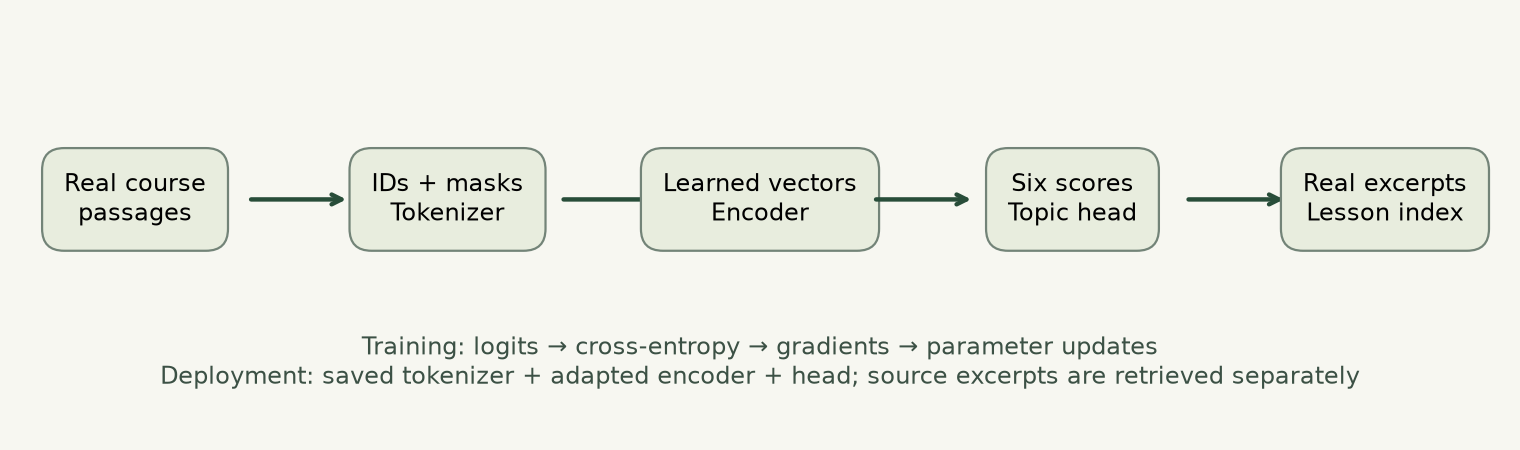

*Training updates parameters. Deployment applies the saved parameters and retrieves attributed course material.*

## 2. Save an inference contract, not just weights

The contract includes the exact model configuration, adapted weights, tokenizer vocabulary and normalization, maximum length, label order, pooling rule and confidence policy. A silent change to any one of these can produce wrong predictions without a shape error.

`artifacts/finetuned.pt` stores trusted tensor weights. `pretrained-source` supplies the encoder configuration and original checkpoint for reproducible loading. The browser only needs the adapted exported graph, tokenizer settings, policy and retrieval index. Hashes identify the exact shipped files.

Never load arbitrary uploaded pickle/checkpoint files. This project only loads its own fixed trusted artifacts with tensor-only loading. Learner input is plain text and never interpreted as HTML or code.

In [2]:
import hashlib
config = json.loads((ROOT / "app/config.json").read_text())
digest = hashlib.sha256((ROOT / "app/model.onnx").read_bytes()).hexdigest()
assert digest == config["model_sha256"]
print("Model SHA-256:", digest)
print("Label order:", config["labels"])
print("Input shape: (1,", config["max_length"], ") int64 for IDs, attention mask and token types")

Model SHA-256: 78ea50be4b338697739a7213145f5d80249d54d460b387f6db455b4849d34555
Label order: ['Foundations & PyTorch', 'Training & evaluation', 'Representations & sequences', 'Transformers & attention', 'Pretrained applications', 'Model adaptation']
Input shape: (1, 96 ) int64 for IDs, attention mask and token types


## 3. Export the actual adapted computation

**ONNX** is a portable representation of a model’s operators and parameters. Export does not train a new model. We put the PyTorch model in evaluation mode and trace the fixed 96-token contract with opset 17. Batch size one matches the interactive app.

The reference model was exported by `scripts/evaluate_export.py`; the cell below can create a separate classroom export. The original file remains untouched. The exported model uses the trained encoder and our masked-mean topic head, not the unadapted base checkpoint.

Source: [ONNX Runtime Web deployment documentation](https://onnxruntime.ai/docs/tutorials/web/deploy.html).

In [3]:
model = load_reference("finetuned")
tokenizer = pretrained_tokenizer()
example = tokenizer("Why is attention useful?", padding="max_length", truncation=True,
                    max_length=MAX_LENGTH, return_tensors="pt")
EXPORT_AGAIN = False
if EXPORT_AGAIN:
    output = ROOT / "artifacts/classroom"; output.mkdir(exist_ok=True)
    torch.onnx.export(model, (example["input_ids"], example["attention_mask"], example["token_type_ids"]),
        str(output / "model.onnx"), input_names=["input_ids", "attention_mask", "token_type_ids"],
        output_names=["logits"], opset_version=17, dynamo=False)
print("Reference ONNX size (MB):", round((ROOT / "app/model.onnx").stat().st_size/1e6, 2))

W1024 10:04:30.421000 54928 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


W1024 10:04:30.489000 54928 site-packages/torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


W1024 10:04:30.502000 54928 site-packages/torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Reference ONNX size (MB): 17.51


## 4. Verify numerical parity before publishing

Two implementations need not be bit-for-bit identical, but their differences must be acceptably small. The reference check compares PyTorch and ONNX logits over 48 inputs: all authored probes, unrelated prompts and tokenizer edge cases. The maximum absolute logit difference is about **6.7 × 10⁻⁶**, below the fixed 10⁻⁴ tolerance.

Tokenizer parity is equally important. JavaScript WordPiece is checked against Hugging Face’s full 96-ID and attention-mask arrays, including accents, Chinese characters, whitespace, special tokens and a very long unknown word. Shape checks alone would miss a wrong word-ID mapping.

In [4]:
import onnxruntime as ort
session = ort.InferenceSession(str(ROOT / "app/model.onnx"), providers=["CPUExecutionProvider"])
fixtures = json.loads((ROOT / "tests/browser-fixtures.json").read_text())
largest_difference = 0.0
for fixture in fixtures:
    ids = np.array([fixture["ids"]], dtype=np.int64)
    mask = np.array([fixture["mask"]], dtype=np.int64)
    actual = session.run(None, {"input_ids": ids, "attention_mask": mask,
                               "token_type_ids": np.zeros_like(ids)})[0][0]
    largest_difference = max(largest_difference, float(np.abs(actual-fixture["logits"]).max()))
assert largest_difference < 1e-4
print("Inputs verified:", len(fixtures), "| Largest logit difference:", largest_difference)

Inputs verified: 48 | Largest logit difference: 6.67572021484375e-06


## 5. Routing and retrieval have different jobs

The neural classifier estimates a broad topic. A **TF-IDF index** ranks actual sections by lexical similarity to the question, with a small 15% preference for the predicted topic. That preference is not another learned model. The index contains the complete public source library so it can return links and literal excerpts.

This is lexical retrieval, not neural semantic search or generated question answering. It can miss synonyms and favor repeated terms. We keep the distinction visible so learners know what each component contributes. A future semantic-retrieval experiment would need its own relevance labels and evaluation.

In [5]:
class LessonIndex:
    """Rank course sections by TF-IDF similarity plus a small topic preference.

    The neural model predicts a topic. This lexical index selects actual source
    excerpts; we do not claim that the classifier generates or explains answers.
    Indexing the full public library is normal retrieval, not classifier fitting.
    """
    def __init__(self):
        self.sections = json.loads((ROOT / "data/sections.json").read_text())
        self.vectorizer = TfidfVectorizer(lowercase=True, strip_accents="unicode", stop_words="english",
                                        ngram_range=(1, 1), max_features=8000, sublinear_tf=True)
        self.matrix = self.vectorizer.fit_transform([row["title"]+" "+row["text"] for row in self.sections])

    def search(self, text: str, topic: int | None = None, limit: int = 4):
        """Return literal excerpts and relevance scores, never invented passages."""
        query = self.vectorizer.transform([text])
        scores = (self.matrix @ query.T).toarray().ravel()
        boosts = np.array([1.15 if row["label"] == topic else 1. for row in self.sections])
        order = (scores * boosts).argsort()[::-1][:limit]
        return [dict(self.sections[i], relevance=float(scores[i])) for i in order if scores[i] > 0]

    def export_browser(self):
        """Persist sparse normalized vectors and the train-independent IDF index."""
        rows = []
        for i, section in enumerate(self.sections):
            vector = self.matrix.getrow(i)
            rows.append(dict(id=section['id'], title=section['title'], topic=section['topic'],
                             label=section['label'], lesson=section['lesson'], url=section['url'],
                             text=section['text'], indices=vector.indices.tolist(), values=vector.data.tolist()))
        return dict(vocabulary={word:int(index) for word,index in self.vectorizer.vocabulary_.items()}, idf=self.vectorizer.idf_.tolist(), sections=rows,
                    stop_words=sorted(self.vectorizer.get_stop_words()))

In [6]:
index = LessonIndex()
question = "Why does my training loss fall while validation gets worse?"
batch = tokenizer(question, padding="max_length", truncation=True, max_length=MAX_LENGTH, return_tensors="pt")
with torch.inference_mode():
    logits = model(batch["input_ids"], batch["attention_mask"], batch["token_type_ids"])
    probabilities = (logits/config["policy"]["temperature"]).softmax(-1)[0]
topic = int(probabilities.argmax())
print("Predicted topic:", LABELS[topic], "| Scaled score:", round(float(probabilities.max()),3))
for section in index.search(question, topic):
    print(section["title"], section["url"], section["text"][:240], sep=" | ")

Predicted topic: Training & evaluation | Scaled score: 0.75
Reading the loss curve | https://solomonpromise.github.io/deep-learning-lab/module-1/lesson-1-3.html#s10 | The loss curve is your primary instrument, and Day 3 is largely devoted to reading it. Start building the habit now. What to look at, in order: Do both curves fall? Yes — the model is learning something that transfers to unseen data. Do the
Looping it: watching loss fall | https://solomonpromise.github.io/deep-learning-lab/module-1/lesson-1-2.html#s10 | One step helped a little. Now do it repeatedly. This cell is a complete training loop written in NumPy — and structurally it is the same loop you will write in PyTorch in Note 1.3, and the same loop that trains models with billions of param
Memorising 500 rows on purpose | https://solomonpromise.github.io/deep-learning-lab/module-3/lesson-3-2.html#s3 | Now we deliberately create the failure we want to study. The model is large relative to the 500 training examples, and we 

## 6. Make failure understandable

The app rejects blank text, caps input at 2,000 characters, and announces when the model truncates content to 94 WordPieces. Model loading is deliberate and reported. The first request downloads the model and runtime; later requests reuse the loaded session. A failed load produces a retryable message.

Low confidence or weak lexical overlap leads to **tentative suggestions**. This is a practical heuristic, not a guarantee against unrelated questions. Sources are always visible. Results are inserted as text nodes; input is never injected as HTML. Native controls, visible focus indicators, status announcements and phone layouts support access.

The runtime is pinned and served with the app, including its license/notices. It uses one WASM thread so GitHub Pages does not need cross-origin isolation headers. The browser’s worker and WebAssembly support remain deployment requirements.

## 7. Run locally, then publish reproducibly

From the project folder:

```sh
python -m http.server 8820 --directory app
```

Open `http://localhost:8820`. A file opened directly with `file://` cannot reliably load a worker, model and data; use an HTTP server. No model training is needed to serve the app.

The GitHub repository contains a Pages workflow that uploads `app/` as the static site. The workflow also copies notebooks into the published downloads. The source, dataset, checkpoints, hashes and evaluation record remain reviewable. Publishing is separate from fitting; a notebook does not automatically push or change a public app.

**Release checklist:** run the split/model/tokenizer checks; execute all notebooks from clean kernels; verify local and public inference; inspect phone layout; check lesson links; record artifact hashes; then publish. `docs/verification.json` records the actual checks completed for this version.

## 8. A classroom demonstration and a maintenance plan

Demonstrate one correct routing result, one ambiguous input and one unrelated request. Show the tokens, uncertainty note and source excerpt. Let learners try their own questions and explain why one successful example is not an evaluation.

For continued improvement, collect feedback with consent, define representative labeled questions, preserve a fresh holdout, compare against the lexical baseline, measure calibration and latency, and monitor broken source links. If the course structure changes, update source attribution and evaluate again. Retraining must produce a new versioned artifact and result record, not overwrite history silently.

The present reference run supports a teaching demo with useful lesson suggestions. It does not establish reliable behavior for arbitrary subjects, multilingual input, high-stakes decisions or actual learner traffic. The same engineering habit from Module 4 applies: describe what the evidence supports.

**Check yourself.** Why might an app return a useful source section even when the topic classifier is wrong? Why is a tokenizer checksum as important as a model checksum?

<details><summary>Worked answers</summary>

Retrieval uses the input’s lexical overlap and only a small topic preference; it can recover a relevant section despite a routing error. Conversely, a correct topic can still produce poor section rankings. The tokenizer defines which embedding rows the model sees; changed normalization or ID assignments invalidate the checkpoint’s meaning even when the model file is unchanged.

</details>

**You now have the full path:** real text → preprocessing → embeddings → recurrent and attention-based models → loss and parameter updates → evaluation → pretrained adaptation → export → a working application.